In [1]:
#202431055_Muhammad Rafi Kurniawan
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#202431055_Muhammad Rafi Kurniawan
CSV_FILE = "populasi_un_clean.csv"

if not os.path.exists(CSV_FILE):
    from google.colab import files
    files.upload()

df = pd.read_csv(CSV_FILE)
display(df.head())

,negara,populasi_2022,populasi_2023,perubahan_persen,benua,subregion
0,India,1.425423e+09,1.438070e+09,0.89,Asia,Southern Asia
1,China,1.425180e+09,1.422585e+09,-0.18,Asia,Eastern Asia
2,United States,3.415340e+08,3.434773e+08,0.57,Americas,Northern America
3,Indonesia,2.788305e+08,2.811901e+08,0.85,Asia,South-eastern Asia
4,Pakistan,2.437007e+08,2.475045e+08,1.56,Asia,Southern Asia


In [3]:
#202431055_Muhammad Rafi Kurniawan
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   negara            237 non-null    object 
 1   populasi_2022     237 non-null    float64
 2   populasi_2023     237 non-null    float64
 3   perubahan_persen  237 non-null    float64
 4   benua             237 non-null    object 
 5   subregion         237 non-null    object 
dtypes: float64(3), object(3)
memory usage: 11.2+ KB


In [4]:
#202431055_Muhammad Rafi Kurniawan
display(df.describe())

,populasi_2022,populasi_2023,perubahan_persen
count,2.370000e+02,2.370000e+02,237.00000
mean,3.384681e+07,3.413909e+07,1.00903
std,1.364027e+08,1.369682e+08,1.58503
min,5.050000e+02,4.960000e+02,-8.08000
25%,3.975380e+05,3.994400e+05,0.18000
50%,5.457801e+06,5.518055e+06,0.96000
75%,2.250904e+07,2.302578e+07,1.94000
max,1.425423e+09,1.438070e+09,6.74000


In [5]:
#202431055_Muhammad Rafi Kurniawan
print(df.isna().sum())

df = df.dropna(subset=["populasi_2023", "perubahan_persen", "benua"]).reset_index(drop=True)
print("\nJumlah data setelah dropna:", len(df))

negara              0
populasi_2022       0
populasi_2023       0
perubahan_persen    0
benua               0
subregion           0
dtype: int64

Jumlah data setelah dropna: 237


In [6]:
#202431055_Muhammad Rafi Kurniawan
print("Kelas unik pada target 'benua':")
print(df["benua"].unique())
print("\nJumlah data per kelas:")
print(df["benua"].value_counts())

Kelas unik pada target 'benua':
['Asia' 'Americas' 'Africa' 'Europe' 'Oceania']

Jumlah data per kelas:
Africa      58
Americas    55
Asia        51
Europe      50
Oceania     23
Name: benua, dtype: int64


In [7]:
#202431055_Muhammad Rafi Kurniawan
X = df.drop(columns=["benua", "negara", "subregion", "populasi_2022"])
y = df["benua"]

print("Fitur yang dipakai:", list(X.columns))
display(X.head())

Fitur yang dipakai: ['populasi_2023', 'perubahan_persen']


,populasi_2023,perubahan_persen
0,1.438070e+09,0.89
1,1.422585e+09,-0.18
2,3.434773e+08,0.57
3,2.811901e+08,0.85
4,2.475045e+08,1.56


In [8]:
#202431055_Muhammad Rafi Kurniawan
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)

x_arr = np.array(X, dtype="float64")
y_arr = np.array(y_encoded, dtype="int64")

print("Bentuk x:", x_arr.shape, x_arr.dtype)
print("Bentuk y:", y_arr.shape, y_arr.dtype)
print("\nPemetaan label -> angka:")
for angka, nama in enumerate(le.classes_):
    print(f"   {angka} = {nama}")

Bentuk x: (237, 2) float64
Bentuk y: (237,) int64

Pemetaan label -> angka:
   0 = Africa
   1 = Americas
   2 = Asia
   3 = Europe
   4 = Oceania


In [9]:
#202431055_Muhammad Rafi Kurniawan
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_arr, y_arr, test_size=0.3, random_state=0
)
print("Data latih:", x_train.shape[0], "| Data uji:", x_test.shape[0])

Data latih: 165 | Data uji: 72


In [10]:
#202431055_Muhammad Rafi Kurniawan
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model.fit(x_train, y_train)

print("Kedalaman pohon  :", model.get_depth())
print("Jumlah daun      :", model.get_n_leaves())

Kedalaman pohon  : 12
Jumlah daun      : 81


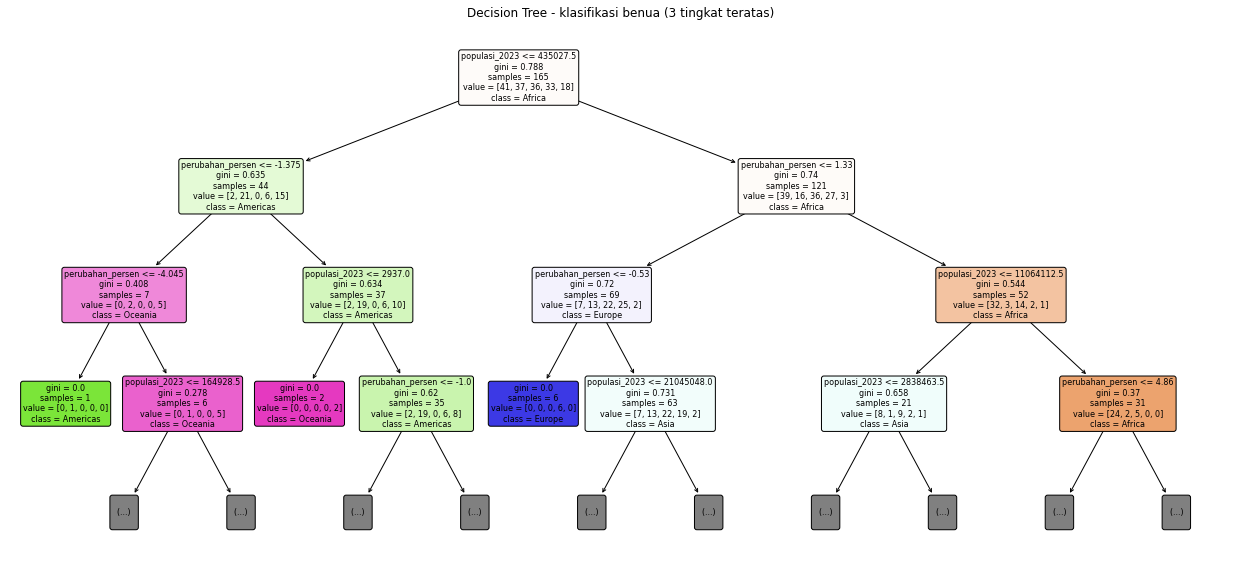

In [11]:
#202431055_Muhammad Rafi Kurniawan
from sklearn import tree

plt.figure(figsize=(22, 10))
tree.plot_tree(
    model,
    max_depth=3,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Decision Tree - klasifikasi benua (3 tingkat teratas)")
plt.show()

In [12]:
#202431055_Muhammad Rafi Kurniawan
print("Urutan fitur:", list(X.columns))

data_baru = np.array([[25_000_000, 2.8]], dtype="float64")
pred = model.predict(data_baru)

print("Prediksi (angka):", pred[0])
print("Prediksi (benua):", le.inverse_transform(pred)[0])

Urutan fitur: ['populasi_2023', 'perubahan_persen']
Prediksi (angka): 0
Prediksi (benua): Africa


In [13]:
#202431055_Muhammad Rafi Kurniawan
from sklearn.metrics import accuracy_score

y_pred = model.predict(x_test)

acc_test  = accuracy_score(y_test, y_pred)
acc_train = accuracy_score(y_train, model.predict(x_train))

print(f"Akurasi data uji   : {acc_test:.4f} ({acc_test*100:.2f}%)")
print(f"Akurasi data latih : {acc_train:.4f} ({acc_train*100:.2f}%)")

Akurasi data uji   : 0.4167 (41.67%)
Akurasi data latih : 1.0000 (100.00%)


In [14]:
#202431055_Muhammad Rafi Kurniawan
from sklearn.metrics import classification_report

print(classification_report(
    y_test, y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0,
))

              precision    recall  f1-score   support

      Africa       0.56      0.59      0.57        17
    Americas       0.37      0.39      0.38        18
        Asia       0.29      0.33      0.31        15
      Europe       0.54      0.41      0.47        17
     Oceania       0.20      0.20      0.20         5

    accuracy                           0.42        72
   macro avg       0.39      0.38      0.39        72
weighted avg       0.43      0.42      0.42        72



In [15]:
#202431055_Muhammad Rafi Kurniawan
print(f"{'max_depth':>10} | {'akurasi latih':>13} | {'akurasi uji':>11}")
for d in [1, 2, 3, 4, 5, 6, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(x_train, y_train)
    print(f"{str(d):>10} | {m.score(x_train, y_train):>13.4f} | {m.score(x_test, y_test):>11.4f}")

 max_depth | akurasi latih | akurasi uji
         1 |        0.3636 |      0.3056
         2 |        0.4909 |      0.4167
         3 |        0.5333 |      0.3611
         4 |        0.6182 |      0.4583
         5 |        0.6485 |      0.4444
         6 |        0.7152 |      0.4167
      None |        1.0000 |      0.3889
